<a href="https://colab.research.google.com/github/mateocgonzalez07/TOI-256/blob/main/2_LBL_HARPS_LHS1140.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LBL sobre HARPS · LHS 1140

Extrae velocidades radiales con LBL (line-by-line) a partir de los `e2ds_A` de HARPS bajados en el notebook de descarga. Se usa `INSTRUMENT='HARPS'` y `DATA_SOURCE='ORIG'` sobre `LHS1140_HARPS/science/LHS1140/`, con el blaze `HARPS_BLAZE_A_72.fits`.

**Resultado:** 293 espectros, RMS de 6.05 m/s y error mediano de 2.84 m/s. Con S/N ≥ 10 quedan 207 espectros, RMS de 5.41 m/s. La tabla queda en Drive (`resultados_LBL/completa/`) y es la entrada del notebook de análisis de RV.

**Orden de uso:** primero `MODO_PRUEBA = True` (3 espectros, ~15 min la primera vez porque baja ~360 MB de modelos). Si da una dispersión de unos 6 m/s, pon `MODO_PRUEBA = False` y corre de nuevo desde la sección 4. La corrida completa tarda 2.5 a 3 h.

**Requisito:** runtime de Python 3.12 (LBL 0.67.008 declara `>=3.12,<3.13`). LBL no está en PyPI y se instala desde GitHub.

**Notas:**
- No hacen falta los `wave_A`: LBL arma la longitud de onda con las 288 claves `ESO DRS CAL TH COEFF LL*` del header de cada `e2ds`.
- `SNR_THRESHOLD`: LBL salta los espectros con S/N(orden 47) por debajo del umbral (10 por defecto). Con 5 entran los 293. El corte a S/N ≥ 10 se hace después, en la tabla de resultados, no en LBL.
- Si la corrida completa se corta, vuelve a correr la sección 6: con `SKIP_LBL_COMPUTE=True` salta los espectros ya calculados (telluclean y la plantilla se rehacen, ~1 h).

**Limitaciones:**
- Se usa un solo blaze para todas las épocas (`BLAZE_POR_NOCHE=False`), no el de cada noche. El blaze de cada noche no está en el archivo de ESO.
- `TEFF = 3213` K solo elige la máscara de líneas. Para el análisis físico de la estrella se usa Teff = 3096 ± 48 K (Cadieux et al. 2024).

## 1. Instalar LBL desde GitHub

LBL no está en PyPI. Se fija el commit para que la corrida sea reproducible. La instalación avisa de conflictos con paquetes de Colab (ipython, pandas, requests); no afectan a LBL, que corre en un proceso aparte.

In [ ]:
COMMIT = 'dbcd813e82c88a8ee873918a5c0176e5b878137a'   # HEAD de GitHub el 2026-11-20 (LBL 0.67.008)
!pip install -q git+https://github.com/njcuk9999/lbl.git@{COMMIT}


### Comprobar la versión instalada
Se comprueba en un proceso nuevo, igual que el wrap de la sección 6.

In [ ]:
!python -c "import lbl, numpy, astropy; print('LBL', lbl.__version__, '| numpy', numpy.__version__, '| astropy', astropy.__version__)"

LBL 0.67.008 | numpy 2.3.3 | astropy 7.2.0


## 2. Importaciones

### Importamos librerías

In [ ]:
import json
import shutil
import socket
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from astropy.io import fits
from google.colab import drive


### Servidores de modelos
Solo informativo: comprueba que los servidores de los modelos responden.

In [ ]:
# Servidores de modelos (solo informativo)
try:
    r = requests.head('http://206.12.93.77/ari/data/lbl/models/tapas_lbl.fits', timeout=20, allow_redirects=True)
    print('TAPAS + gradientes : responde (status', r.status_code, ')')
except Exception as e:
    print('TAPAS + gradientes : SIN respuesta ->', e)
try:
    socket.create_connection(('phoenix.astro.physik.uni-goettingen.de', 21), timeout=20).close()
    print('PHOENIX (FTP)      : responde')
except Exception as e:
    print('PHOENIX (FTP)      : SIN respuesta ->', e)

## 3. Parámetros y Drive

In [ ]:
drive.mount('/content/drive')

DRIVE = Path('/content/drive/MyDrive/LHS1140_HARPS')   # science/, calib/, HARPS_BLAZE_A_72.fits
OBJETO = 'LHS1140'
TEFF = 3213                  # K (M4.5V); solo afecta la máscara de líneas (en el análisis se usa 3096 K)
SNR_THRESHOLD = 5            # umbral de LBL (por defecto 10)

MODO_PRUEBA = False           # True: 3 espectros; False: todos
BLAZE_POR_NOCHE = False      # False: un solo blaze (HARPS_BLAZE_A_72.fits) para todo, como en la prueba validada
                             # True: usa los 147 blazes de calib/ (LBL toma el nombre de ESO DRS BLAZE FILE)
DATA_DIR_EN_DRIVE = True    # True: DATA_DIR en Drive (más lento, pero sobrevive a una desconexión)

base = (DRIVE / 'lbl_data') if DATA_DIR_EN_DRIVE else Path('/content/lbl_data')
DATA_DIR = base / ('prueba' if MODO_PRUEBA else 'completa')   # prueba y corrida completa no se mezclan
DATA_DIR.mkdir(parents=True, exist_ok=True)

v = sys.version_info
print(f'Python {v.major}.{v.minor}.{v.micro} | DATA_DIR = {DATA_DIR}')
assert (v.major, v.minor) == (3, 12), (
    'Usa Python 3.12: Entorno de ejecución -> Cambiar tipo de entorno -> versión 2026.07 -> Reconectar')

## 4. Copiar los datos de Drive a `DATA_DIR`

In [ ]:
K_SNR = 'ESO DRS SPE EXT SN47'
K_BLAZE = 'ESO DRS BLAZE FILE'
BLAZE_UNICO = 'HARPS_BLAZE_A_72.fits'

sci_src, cal_src = DRIVE / 'science' / OBJETO, DRIVE / 'calib'
sci_dst, cal_dst, mod_dst = (DATA_DIR / 'science' / OBJETO), (DATA_DIR / 'calib'), (DATA_DIR / 'models')
for d in (sci_dst, cal_dst, mod_dst):
    d.mkdir(parents=True, exist_ok=True)

todos = sorted(sci_src.glob('*e2ds_A.fits'))
print(len(todos), 'e2ds en Drive')

if MODO_PRUEBA:
    # los 3 días de la prueba local validada (los milisegundos del nombre pueden diferir)
    elegidos = []
    for dia in ('2015-11-23', '2015-11-27', '2015-11-28'):
        cand = sorted(sci_src.glob(f'HARPS.{dia}T*_e2ds_A.fits'))
        if cand:
            elegidos.append(cand[0])
    if len(elegidos) < 3:   # plan B: repartidos en el tiempo y con S/N suficiente
        elegidos = []
        for i in np.linspace(0, len(todos) - 1, 12).astype(int):
            if fits.getheader(todos[i]).get(K_SNR, 0) >= max(SNR_THRESHOLD, 10):
                elegidos.append(todos[i])
            if len(elegidos) == 3:
                break
else:
    elegidos = todos

for f in elegidos:
    if not (sci_dst / f.name).exists():
        shutil.copy2(f, sci_dst / f.name)

# blaze(s)
if BLAZE_POR_NOCHE:
    faltan = []
    for f in sci_dst.glob('*e2ds_A.fits'):
        b = fits.getheader(f).get(K_BLAZE)
        if not (cal_dst / b).exists():
            if (cal_src / b).exists():
                shutil.copy2(cal_src / b, cal_dst / b)
            else:
                faltan.append(b)
    print('Blazes por noche en calib/:', len(list(cal_dst.glob('*_blaze_A.fits'))), '| faltan:', faltan)
else:
    origen = next((p for p in (DRIVE / BLAZE_UNICO, Path('/content') / BLAZE_UNICO) if p.exists()), None)
    assert origen is not None, 'No encuentro HARPS_BLAZE_A_72.fits (ni en LHS1140_HARPS/ ni en /content)'
    shutil.copy2(origen, cal_dst / BLAZE_UNICO)
    print('Blaze único:', cal_dst / BLAZE_UNICO)

# modelos ya descargados en una corrida anterior (evita bajar ~360 MB otra vez)
if (DRIVE / 'models').exists():
    for f in (DRIVE / 'models').glob('*'):
        if f.is_file() and not (mod_dst / f.name).exists():
            shutil.copy2(f, mod_dst / f.name)
print('Espectros en DATA_DIR:', len(list(sci_dst.glob('*e2ds_A.fits'))), '| modelos locales:', len(list(mod_dst.glob('*'))))

293 e2ds en Drive
Blaze único: /content/drive/MyDrive/LHS1140_HARPS/lbl_data/completa/calib/HARPS_BLAZE_A_72.fits
Espectros en DATA_DIR: 293 | modelos locales: 10


## 5. QC de lo que va a leer LBL

Debe haber un solo objeto, 288 coeficientes de wave por espectro y blaze finito. Con `SNR_THRESHOLD = 5` ningún espectro queda por debajo del umbral.

In [ ]:
filas = []
for f in sorted(sci_dst.glob('*e2ds_A.fits')):
    h = fits.getheader(f)
    filas.append(dict(archivo=f.name, objeto=h.get('ESO OBS TARG NAME'), snr47=h.get(K_SNR),
                      n_coef_wave=sum(1 for k in h if k.startswith('ESO DRS CAL TH COEFF LL')),
                      rjd=h.get('ESO DRS BJD') - 2400000, berv=h.get('ESO DRS BERV'),
                      blaze=h.get(K_BLAZE)))
hdr_df = pd.DataFrame(filas)

blz = fits.getdata(cal_dst / BLAZE_UNICO) if not BLAZE_POR_NOCHE else None   # igual que LBL: primer HDU con datos
print(len(hdr_df), 'espectros | objetos:', hdr_df.objeto.unique().tolist())
print('Coeficientes de wave (debe ser 288):', hdr_df.n_coef_wave.unique().tolist())
if blz is not None:
    print('Blaze:', blz.shape, '| finito:', bool(np.isfinite(blz).all()))
print('S/N47: min %.1f  mediana %.1f  max %.1f' % (hdr_df.snr47.min(), hdr_df.snr47.median(), hdr_df.snr47.max()))
print('Con S/N < 10:', int((hdr_df.snr47 < 10).sum()), '| con S/N < SNR_THRESHOLD (LBL los salta):', int((hdr_df.snr47 < SNR_THRESHOLD).sum()))
assert (hdr_df.n_coef_wave == 288).all() and (hdr_df.objeto == OBJETO).all()

293 espectros | objetos: ['LHS1140']
Coeficientes de wave (debe ser 288): [288]
Blaze: (72, 4096) | finito: True
S/N47: min 5.6  mediana 11.8  max 17.5
Con S/N < 10: 86 | con S/N < SNR_THRESHOLD (LBL los salta): 0


## 6. Correr LBL

Se corre en un proceso aparte (`lbl_wrap`) con los parámetros guardados en un JSON. Con `OBJECT_COMPARISON=[OBJETO]` la plantilla se hace con los propios datos.

In [ ]:
rparams = dict(
    INSTRUMENT='HARPS',
    DATA_SOURCE='ORIG',                  # e2ds del DRS original (NO 'ESO' = HARPS_ESO, que ignoraría el blaze)
    DATA_DIR=str(DATA_DIR),
    OBJECT_SCIENCE=[OBJETO],
    OBJECT_COMPARISON=[OBJETO],          # plantilla con los propios datos
    DATA_TYPES=['SCIENCE'],
    OBJECT_TEFF=[TEFF],
    BLAZE_FILE=None if BLAZE_POR_NOCHE else BLAZE_UNICO,
    BLAZE_CORRECTED=False,               # los e2ds_A no vienen corregidos por blaze
    INPUT_FILE='*e2ds_A.fits',           # solo fibra A
    SNR_THRESHOLD=SNR_THRESHOLD,
    RUN_LBL_TELLUCLEAN=True, RUN_LBL_TEMPLATE=True, RUN_LBL_MASK=True,
    RUN_LBL_COMPUTE=True, RUN_LBL_COMPILE=True,
    # SKIP_* = "salta si el resultado ya existe" (así se puede reanudar)
    SKIP_LBL_TEMPLATE=False, SKIP_LBL_MASK=False,
    SKIP_LBL_COMPUTE=True, SKIP_LBL_COMPILE=False,
    VERBOSE=2, PLOT=False,
)
RUN = Path('/content/lbl_run'); RUN.mkdir(exist_ok=True)
PARAMS_JSON, RUNNER = RUN / 'rparams.json', RUN / 'run_lbl.py'
PARAMS_JSON.write_text(json.dumps(rparams, indent=1))
RUNNER.write_text('import json, sys\nfrom lbl import lbl_wrap\nlbl_wrap(json.load(open(sys.argv[1])))\n')

!python {RUNNER} {PARAMS_JSON}

Se truncaron las últimas líneas 5000 del resultado de transmisión.
2026-11-21 01:02:31.071|G| 		Iteration duration: 4.9778
2026-11-21 01:02:31.072|G| 		RV = 14.61 m/s, sigma = 3.62 m/s
2026-11-21 01:02:31.073|G| 	--------------------------------------------------
2026-11-21 01:02:31.074|G| 	Iteration 2
2026-11-21 01:02:31.074|G| 	--------------------------------------------------
2026-11-21 01:02:35.485|G| 		stdev_meas/stdev_pred = 1.06
2026-11-21 01:02:35.487|G| 		Iteration 1: bulk error: 3.62 m/s rv = 15338.94 m/s
2026-11-21 01:02:35.488|G| 		Iteration duration: 4.4113
2026-11-21 01:02:35.488|G| 		RV = -1.03 m/s, sigma = 3.62 m/s
2026-11-21 01:02:35.489|G| 		Converged RV = -1.03 m/s, sigma = 3.62 m/s
2026-11-21 01:02:35.490|G| 	--------------------------------------------------
2026-11-21 01:02:35.490|G| 	Iteration 3
2026-11-21 01:02:35.491|G| 	--------------------------------------------------
2026-11-21 01:02:41.217|G| 		stdev_meas/stdev_pred = 1.06
2026-11-21 01:02:41.219|G| 		Ite

## 7. Resultados

Lectura de la tabla final (`.rdb`), RMS con y sin el corte S/N ≥ 10 y gráfica de la RV.

Tabla: lbl_LHS1140_tc_LHS1140_tc.rdb
todos      N=293  RMS=  6.05 m/s  error mediano= 2.84 m/s
S/N >= 10  N=207  RMS=  5.41 m/s  error mediano= 2.59 m/s


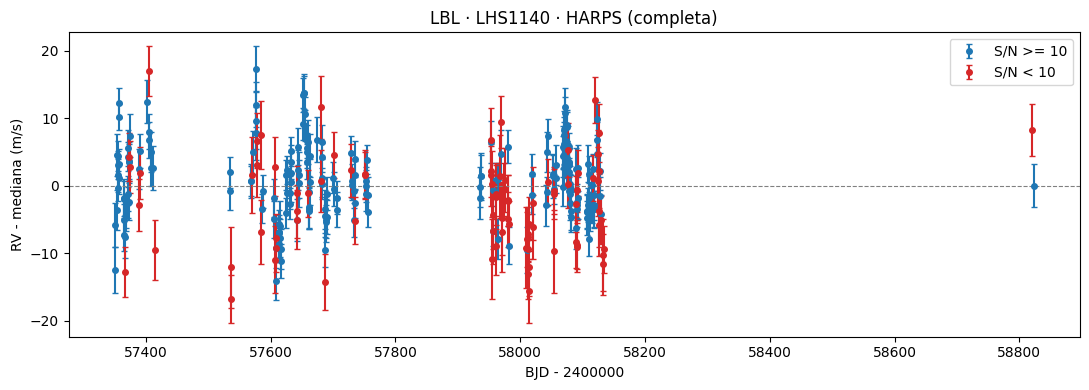

In [ ]:
rdb_dir = DATA_DIR / 'lblrdb'
cands = sorted(rdb_dir.glob(f'lbl_{OBJETO}_tc_{OBJETO}_tc.rdb')) or sorted(
    p for p in rdb_dir.glob('*.rdb') if not p.name.startswith('lbl2'))
assert cands, f'No hay tabla final en {rdb_dir}; revisa la salida de la celda anterior y {DATA_DIR}/log/'
rdb = cands[0]
print('Tabla:', rdb.name)

rv = pd.read_csv(rdb, sep='\t', skiprows=[1])     # la línea 2 de un .rdb son guiones
for c in rv.columns:
    if c != 'DATE-OBS':
        rv[c] = pd.to_numeric(rv[c], errors='coerce')
rv = rv.rename(columns={'HIERARCH ESO DRS BERV': 'berv', 'HIERARCH ESO DRS SPE EXT SN47': 'snr47'})
rv = rv.sort_values('rjd').reset_index(drop=True)

def resumen(d, etiqueta):
    w = 1 / d.svrad**2
    media = np.sum(w * d.vrad) / np.sum(w)
    print('%-10s N=%3d  RMS=%6.2f m/s  error mediano=%5.2f m/s' % (etiqueta, len(d), (d.vrad - media).std(ddof=1), d.svrad.median()))
resumen(rv, 'todos')
resumen(rv[rv.snr47 >= 10], 'S/N >= 10')
if MODO_PRUEBA:
    print('Referencia local (2015-11-23/27/28): -13620.59 / -13608.66 / -13616.87 m/s, dispersión 6.1 m/s.')
    print('Si salieron otros espectros, compara la dispersión y no los valores.')
    print(rv[['DATE-OBS', 'vrad', 'svrad', 'berv', 'snr47']].to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 4))
for mask, color, lab in ((rv.snr47 >= 10, 'C0', 'S/N >= 10'), (rv.snr47 < 10, 'C3', 'S/N < 10')):
    d = rv[mask]
    if len(d):
        ax.errorbar(d.rjd, d.vrad - rv.vrad.median(), d.svrad, fmt='o', ms=4, capsize=2, color=color, label=lab)
ax.axhline(0, color='gray', ls='--', lw=0.8)
ax.set_xlabel('BJD - 2400000'); ax.set_ylabel('RV - mediana (m/s)')
ax.set_title(f'LBL · {OBJETO} · HARPS ({"prueba" if MODO_PRUEBA else "completa"})'); ax.legend()
plt.tight_layout(); plt.savefig(DATA_DIR / 'rv_LHS1140.png', dpi=150); plt.show()

## 8. Respaldo en Drive

Se guardan los resultados y los modelos descargados, para no bajarlos otra vez.

In [ ]:
out = DRIVE / 'resultados_LBL' / ('prueba' if MODO_PRUEBA else 'completa')
out.mkdir(parents=True, exist_ok=True)
cols = [c for c in ('DATE-OBS', 'rjd', 'vrad', 'svrad', 'berv', 'snr47', 'CRX') if c in rv.columns]
rv[cols].assign(bjd=rv.rjd + 2400000.0).to_csv(out / 'RV_LHS1140.csv', index=False)
shutil.copy2(DATA_DIR / 'rv_LHS1140.png', out / 'rv_LHS1140.png')
for p in rdb_dir.glob('*.rdb'):
    shutil.copy2(p, out / p.name)

(DRIVE / 'models').mkdir(exist_ok=True)
for f in mod_dst.glob('*'):
    if f.is_file() and not (DRIVE / 'models' / f.name).exists():
        shutil.copy2(f, DRIVE / 'models' / f.name)
print('Guardado en', out, '| modelos en', DRIVE / 'models')

Guardado en /content/drive/MyDrive/LHS1140_HARPS/resultados_LBL/completa | modelos en /content/drive/MyDrive/LHS1140_HARPS/models
